In [41]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [42]:
df=pd.read_csv('On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2026_8.csv')

C:\Users\ZRS\AppData\Local\Temp\ipykernel_6208\3604778232.py:1: DtypeWarning: Columns (77,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2026_8.csv')


In [43]:
print('shape:' , df.shape)
display(df.head(5))
df.info

shape: (608389, 110)


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,...,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109
0,2026,3,8,23,7,2026-08-23,DL,19790,DL,N542DE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026,3,8,23,7,2026-08-23,DL,19790,DL,N542DE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026,3,8,24,1,2026-08-24,DL,19790,DL,N550DN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026,3,8,24,1,2026-08-24,DL,19790,DL,N550DN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026,3,8,25,2,2026-08-25,DL,19790,DL,N924DZ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<bound method DataFrame.info of         Year  Quarter  Month  DayofMonth  DayOfWeek  FlightDate  \
0       2026        3      8          23          7  2026-08-23   
1       2026        3      8          23          7  2026-08-23   
2       2026        3      8          24          1  2026-08-24   
3       2026        3      8          24          1  2026-08-24   
4       2026        3      8          25          2  2026-08-25   
...      ...      ...    ...         ...        ...         ...   
608384  2026        3      8          20          4  2026-08-20   
608385  2026        3      8          21          5  2026-08-21   
608386  2026        3      8          21          5  2026-08-21   
608387  2026        3      8          22          6  2026-08-22   
608388  2026        3      8          22          6  2026-08-22   

       Reporting_Airline  DOT_ID_Reporting_Airline  \
0                     DL                     19790   
1                     DL                     19790   
2

In [44]:
status_summery=pd.DataFrame({
    'canselled': df['Cancelled'].value_counts(),
    'Diverted' : df['Diverted'].value_counts()

})
display(status_summery)

,canselled,Diverted
0.0,597076,605520
1.0,11313,2869


In [45]:
total_flights_calselledORdiverted=11313+2869
percentage_total_flights_canselledORdiverted=14182/608389 *100
print(f'percentage total flights canselled or diverted :{percentage_total_flights_canselledORdiverted.__round__(2)}%')


percentage total flights canselled or diverted :2.33%


In [46]:
delay_summery=df['ArrDel15'].value_counts(dropna=False)
print(f'delay summery{delay_summery}')

delay summeryArrDel15
0.0    434571
1.0    159636
NaN     14182
Name: count, dtype: int64


In [47]:
delay_summary = df['ArrDel15'].value_counts(dropna=False)

delay_summary = pd.DataFrame({
    'Count': delay_summary,
    'Percentage': (delay_summary / len(df) * 100).round(2)
})

display(delay_summary)

,Count,Percentage
ArrDel15,,
0.0,434571,71.43
1.0,159636,26.24
NaN,14182,2.33


In [48]:
departure_delay_summary = df['DepDel15'].value_counts(dropna=False)

departure_delay_summary = pd.DataFrame({
    'Count': departure_delay_summary,
    'Percentage': (
        departure_delay_summary / len(df) * 100
    ).round(2)
})

display(departure_delay_summary)

,Count,Percentage
DepDel15,,
0.0,437667,71.94
1.0,160067,26.31
NaN,10655,1.75


In [49]:
delay_comperison=pd.crosstab(
    df['DepDel15'],
    df['ArrDel15'],
    margins=True,
    dropna=False
)
delay_comperison

ArrDel15,0.0,1.0,NaN,All
DepDel15,,,,
0.0,407514,28343,1810,437667.0
1.0,27057,131293,1717,160067.0
NaN,0,0,10655,NaN
All,434571,159636,0,608389.0


In [50]:
delay_comperison=pd.crosstab(
    df['DepDel15'],
    df['ArrDel15'],
    
    normalize='index'
)*100
display(delay_comperison.round(2))

ArrDel15,0.0,1.0
DepDel15,,
0.0,93.50,6.50
1.0,17.09,82.91


### Analysis 01: Relationship Between Departure and Arrival Delays

**Objective**

Investigate the relationship between departure delays and arrival delays to understand how departure delays affect flight arrival performance.

**Findings**

- 82.91% of flights departing with a delay of 15 minutes or more also arrived with a delay of 15 minutes or more.
- Only 6.50% of flights departing on time experienced an arrival delay of 15 minutes or more.
- 17.09% of delayed departures arrived on time, indicating that some flights recovered lost time during the journey.

**Key Insight**

Departure delays are strongly associated with arrival delays. However, some flights manage to recover lost time during their journey.

In [51]:
df['ArrDelayMinutes'].describe()

count    594207.000000
mean         21.975958
std          63.861358
min           0.000000
25%           0.000000
50%           0.000000
75%          17.000000
max        4381.000000
Name: ArrDelayMinutes, dtype: float64

In [52]:
delay_distribution = pd.DataFrame({
    'Count': [
        (df['ArrDelayMinutes'] == 0).sum(),
        (df['ArrDelayMinutes'] > 0).sum()
    ]
}, index=['On-Time', 'Delayed'])

delay_distribution['Percentage'] = (
    delay_distribution['Count'] / df['ArrDelayMinutes'].notna().sum() * 100
).round(2)

display(delay_distribution)

,Count,Percentage
On-Time,346649,58.34
Delayed,247558,41.66


In [53]:
bins = [-1, 0, 15, 30, 60, 120, float('inf')]

labels = [
    'On-Time',
    '1-15 min',
    '16-30 min',
    '31-60 min',
    '61-120 min',
    'Above 120 min'
]

df['ArrivalDelayCategory'] = pd.cut(
    df['ArrDelayMinutes'],
    bins=bins,
    labels=labels
)

delay_categories = df['ArrivalDelayCategory'].value_counts().sort_index()

display(pd.DataFrame({
    'Count': delay_categories,
    'Percentage': (delay_categories / df['ArrDelayMinutes'].notna().sum() * 100).round(2)
}))

,Count,Percentage
ArrivalDelayCategory,,
On-Time,346649,58.34
1-15 min,92074,15.50
16-30 min,45747,7.70
31-60 min,46165,7.77
61-120 min,36562,6.15
Above 120 min,27010,4.55


### Analysis 02: Arrival Delay Distribution

**Objective**

Analyze the distribution of arrival delays to understand how frequently flights experience delays and how severe those delays are.

**Findings**

- 58.34% of flights arrived without any delay.
- 41.66% of flights experienced at least one minute of arrival delay.
- 15.50% experienced delays between 1 and 15 minutes.
- 18.47% experienced delays exceeding 30 minutes.
- 10.70% experienced delays exceeding 60 minutes.
- 4.55% experienced delays exceeding 120 minutes.

**Key Insight**

Although most flights arrived on time, a considerable proportion experienced delays. In particular, 10.70% of flights had delays exceeding one hour, indicating that long delays remain an important operational issue.

In [54]:
%matplotlib inline

C:\Users\ZRS\AppData\Local\Temp\ipykernel_6208\1128343374.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


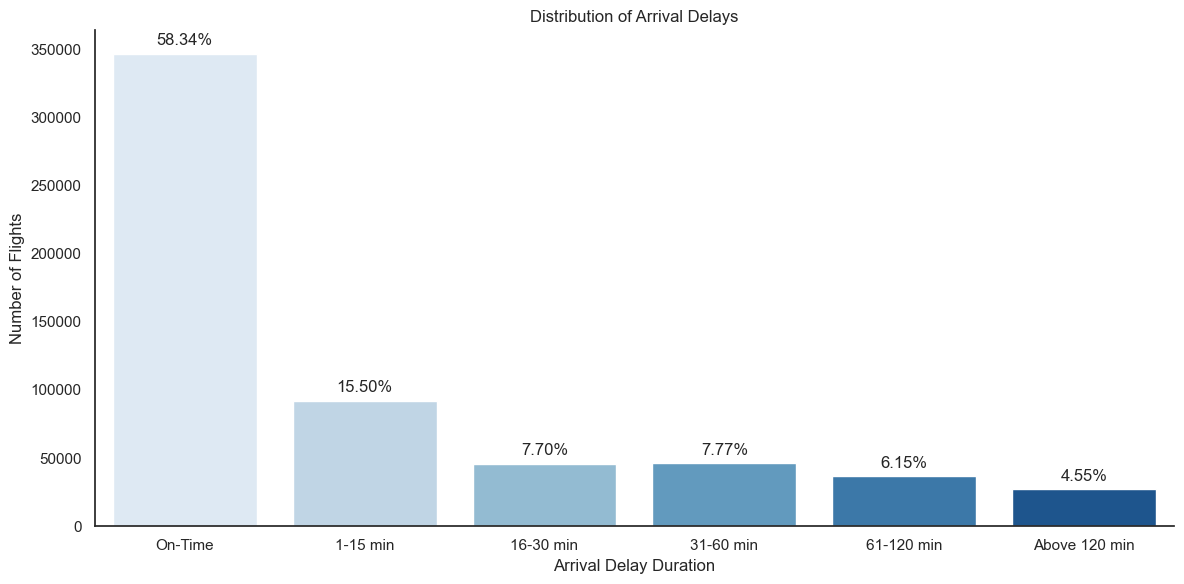

In [62]:
fig, ax = plt.subplots(figsize=(12, 6))

percentages = delay_categories / delay_categories.sum() * 100

colors = sns.color_palette('Blues', n_colors=len(delay_categories))

sns.barplot(
    x=delay_categories.index,
    y=delay_categories.values,
    palette=colors,
    ax=ax
)

ax.set_title('Distribution of Arrival Delays')
ax.set_xlabel('Arrival Delay Duration')
ax.set_ylabel('Number of Flights')

for bar, percentage in zip(ax.patches, percentages):
    ax.annotate(
        f'{percentage:.2f}%',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=0)
plt.tight_layout()

display(fig)
plt.close(fig)

In [63]:
airline_delay_summary = df.groupby('Reporting_Airline').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

airline_delay_summary['DelayRate'] = (
    airline_delay_summary['DelayedFlights'] /
    airline_delay_summary['TotalFlights'] * 100
).round(2)

airline_delay_summary['AvgArrivalDelay'] = (
    airline_delay_summary['AvgArrivalDelay'].round(2)
)

display(
    airline_delay_summary.sort_values(
        'DelayRate',
        ascending=False
    )
)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
Reporting_Airline,,,,
B6,22145,7968.0,32.99,35.98
F9,19638,6565.0,31.08,33.43
OH,19304,6104.0,33.79,31.62
WN,114752,34312.0,18.96,29.90
AA,82801,23564.0,26.23,28.46
UA,72757,20433.0,24.57,28.08
G4,9926,2602.0,27.35,26.21
OO,74292,18265.0,22.08,24.59
AS,30829,7546.0,14.20,24.48


### Analysis 03: Arrival Delay Performance by Airline

**Objective**

Compare airline performance based on arrival delay rates and average arrival delay duration.

**Findings**

- B6 recorded the highest arrival delay rate at 35.98%.
- F9 and OH followed with delay rates of 33.43% and 31.62%, respectively.
- MQ had the lowest arrival delay rate at 20.16%.
- OH recorded the highest average arrival delay at 33.79 minutes.
- AS had the lowest average arrival delay at 14.20 minutes.
- WN operated the highest number of flights, with 114,752 flights.

**Key Insight**

Airline performance varies depending on the delay metric used. A higher delay rate does not necessarily indicate a higher average delay duration. Therefore, both metrics should be considered when evaluating airline performance.

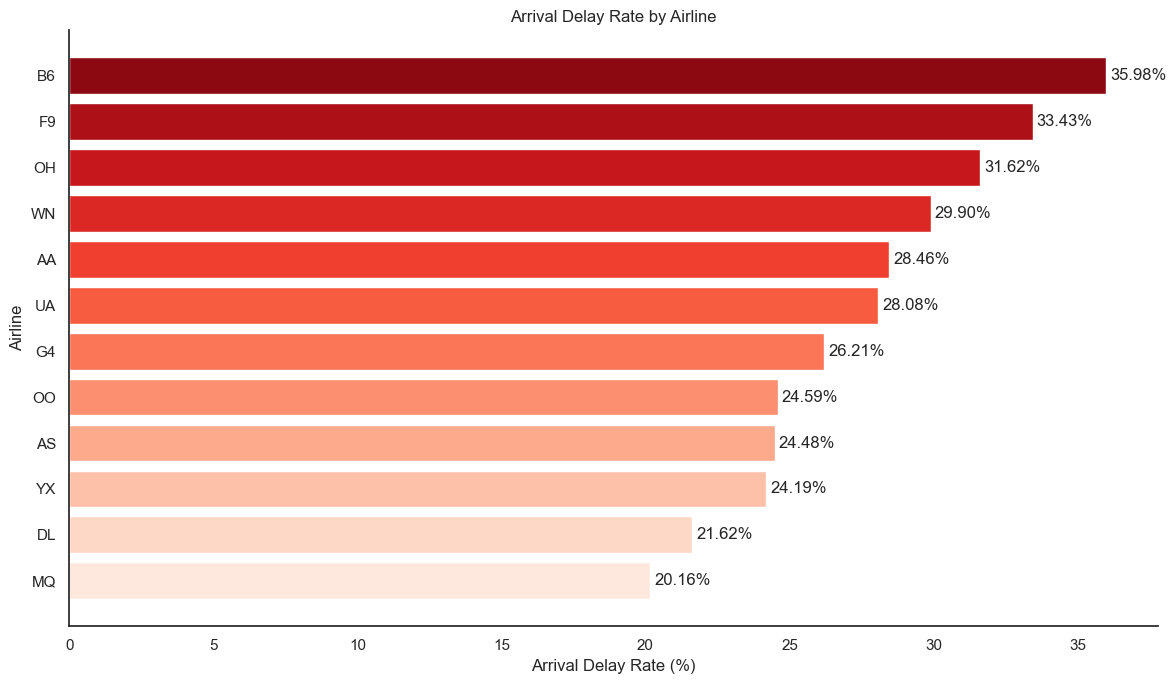

In [65]:
plot_data = airline_delay_summary.sort_values(
    'DelayRate',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette(
    'Reds',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['DelayRate'],
    color=colors
)

ax.set_title('Arrival Delay Rate by Airline')
ax.set_xlabel('Arrival Delay Rate (%)')
ax.set_ylabel('Airline')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

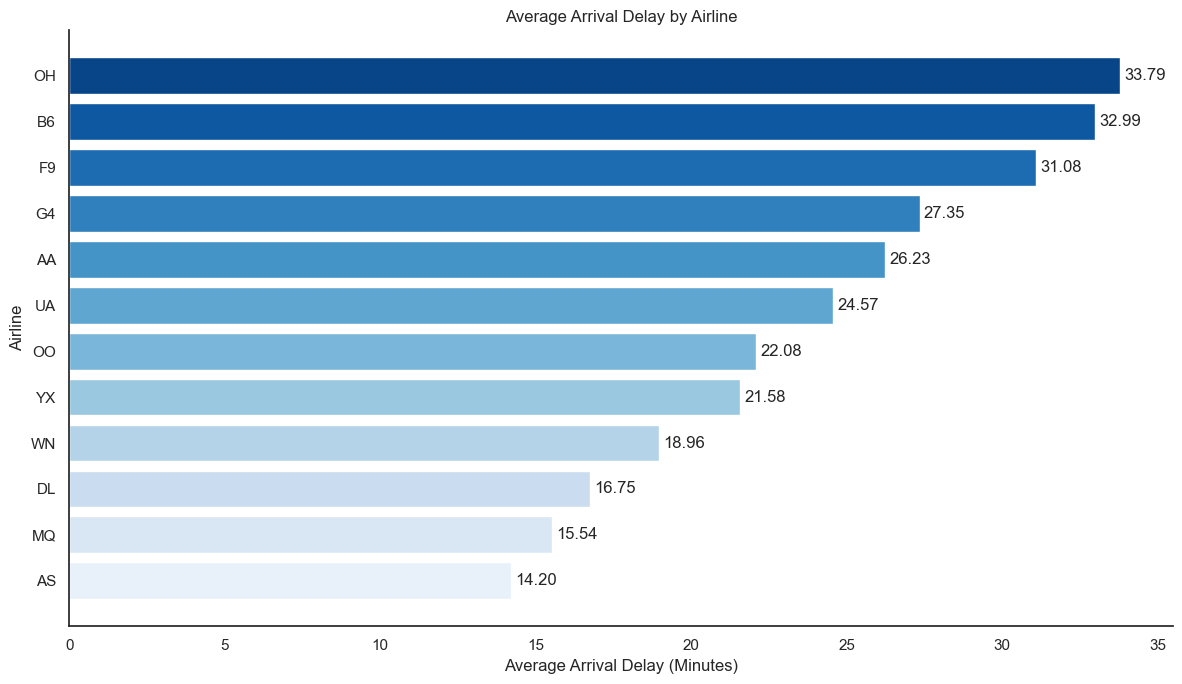

In [66]:
plot_data = airline_delay_summary.sort_values(
    'AvgArrivalDelay',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette(
    'Blues',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['AvgArrivalDelay'],
    color=colors
)

ax.set_title('Average Arrival Delay by Airline')
ax.set_xlabel('Average Arrival Delay (Minutes)')
ax.set_ylabel('Airline')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [67]:
df['ScheduledDepartureHour'] = df['CRSDepTime'] // 100

In [68]:
hourly_delay_summary = df.groupby('ScheduledDepartureHour').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

hourly_delay_summary['DelayRate'] = (
    hourly_delay_summary['DelayedFlights'] /
    hourly_delay_summary['TotalFlights'] * 100
).round(2)

hourly_delay_summary['AvgArrivalDelay'] = (
    hourly_delay_summary['AvgArrivalDelay'].round(2)
)

display(hourly_delay_summary)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
ScheduledDepartureHour,,,,
0,947,200.0,14.90,21.12
1,234,26.0,7.86,11.11
2,70,10.0,8.46,14.29
3,60,13.0,12.02,21.67
5,14175,1075.0,9.43,7.58
6,41185,3752.0,9.33,9.11
7,45291,5419.0,10.08,11.96
8,42514,6325.0,10.94,14.88
9,34734,6106.0,12.19,17.58


### Analysis 04: Arrival Delay Performance by Scheduled Departure Hour

**Objective**

Investigate how scheduled departure time is associated with arrival delay performance.

**Findings**

- The lowest arrival delay rate occurred at 05:00, with 7.58%.
- The highest arrival delay rate occurred at 19:00, with 41.40%.
- Arrival delay rates generally increased from early morning until evening.
- After 19:00, the delay rate gradually decreased.
- The highest average arrival delay was also recorded at 19:00, reaching 35.23 minutes.

**Key Insight**

Flights scheduled for evening departure generally experienced higher arrival delay rates and longer average delays than early-morning flights. However, this association does not establish causation, and differences in flight volume should be considered when interpreting the results.

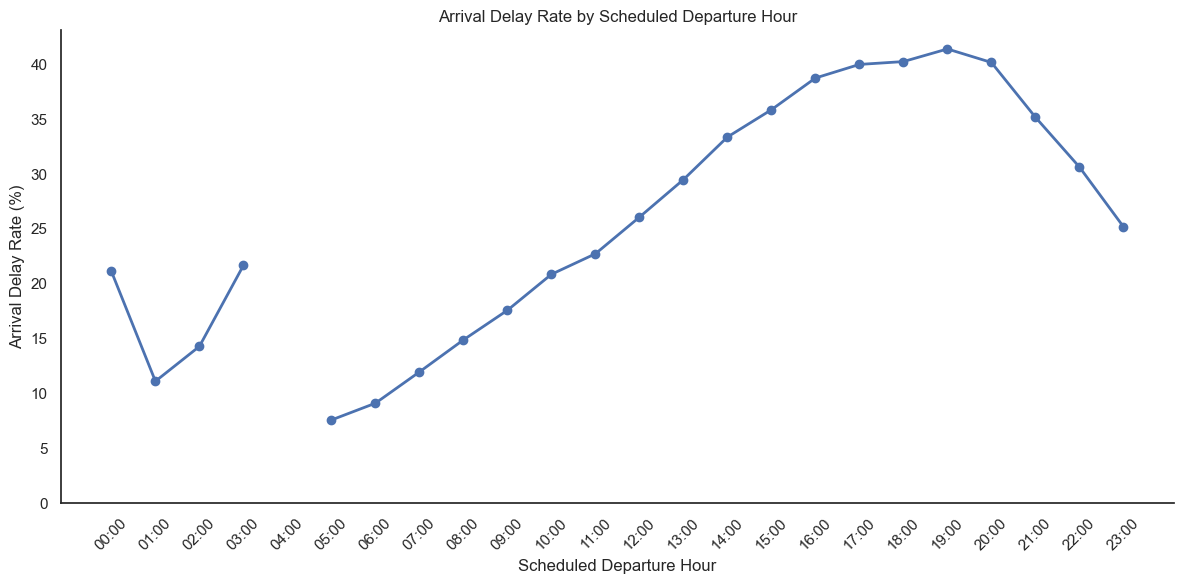

In [74]:
hourly_plot = hourly_delay_summary.reindex(range(24))

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    hourly_plot.index,
    hourly_plot['DelayRate'],
    marker='o',
    linewidth=2
)

ax.set_title('Arrival Delay Rate by Scheduled Departure Hour')
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Arrival Delay Rate (%)')

ax.set_xticks(range(24))
ax.set_xticklabels(
    [f'{hour:02d}:00' for hour in range(24)],
    rotation=45
)

ax.set_ylim(bottom=0)

plt.tight_layout()

display(fig)
plt.close(fig)

In [75]:
weekday_delay_summary = df.groupby('DayOfWeek').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

weekday_delay_summary['DelayRate'] = (
    weekday_delay_summary['DelayedFlights'] /
    weekday_delay_summary['TotalFlights'] * 100
).round(2)

weekday_delay_summary['AvgArrivalDelay'] = (
    weekday_delay_summary['AvgArrivalDelay'].round(2)
)

display(weekday_delay_summary)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
DayOfWeek,,,,
1,99564,27590.0,22.94,27.71
2,72898,14476.0,16.61,19.86
3,74191,16080.0,16.15,21.67
4,79457,23672.0,25.48,29.79
5,79034,24219.0,24.70,30.64
6,87285,21551.0,19.50,24.69
7,101778,32048.0,26.40,31.49


### Analysis 05: Arrival Delay Performance by Day of Week

**Objective**

Analyze arrival delay patterns across different days of the week to identify variations in flight performance.

**Findings**

- Sunday recorded the highest arrival delay rate at 31.49%.
- Tuesday had the lowest arrival delay rate at 19.86%.
- Sunday also recorded the highest average arrival delay at 26.40 minutes.
- Wednesday had the lowest average arrival delay at 16.15 minutes.
- Thursday, Friday, and Sunday experienced relatively higher arrival delay rates.
- Sunday had the highest flight volume, with 101,778 flights.

**Key Insight**

Flight delay performance varies across the week. Sunday shows the weakest performance in terms of both delay rate and average arrival delay, while Tuesday has the lowest delay rate.

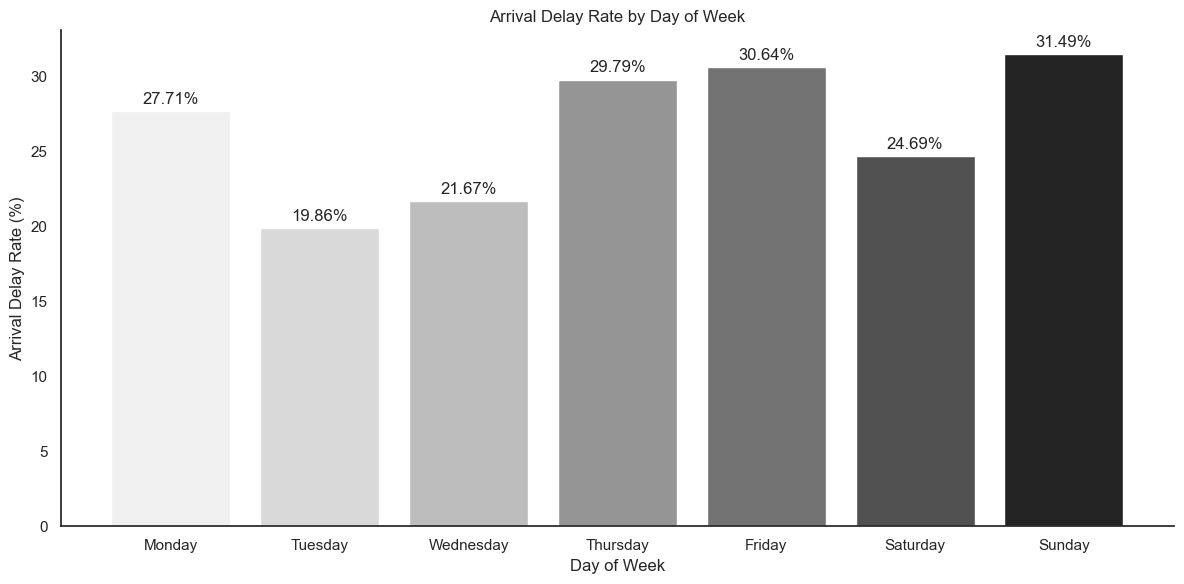

In [83]:
plot_data = weekday_delay_summary.copy()

days = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette(
    'Grays',
    n_colors=len(plot_data)
)

ax.bar(
    days,
    plot_data['DelayRate'],
    color=colors
)

ax.set_title('Arrival Delay Rate by Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Arrival Delay Rate (%)')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [84]:
destination_delay_summary = df.groupby('Dest').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

destination_delay_summary['DelayRate'] = (
    destination_delay_summary['DelayedFlights'] /
    destination_delay_summary['TotalFlights'] * 100
).round(2)

destination_delay_summary['AvgArrivalDelay'] = (
    destination_delay_summary['AvgArrivalDelay'].round(2)
)

display(
    destination_delay_summary.sort_values(
        'TotalFlights',
        ascending=False
    ).head(15)
)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
Dest,,,,
ORD,32130,10287.0,33.75,32.02
DEN,27768,8264.0,26.58,29.76
DFW,27132,5453.0,18.32,20.10
ATL,26788,5712.0,18.55,21.32
LAX,16334,4035.0,18.27,24.70
SEA,15770,4150.0,16.66,26.32
CLT,14825,3461.0,23.52,23.35
PHX,14561,3218.0,17.90,22.10
LAS,13675,3860.0,20.66,28.23


### Analysis 06: Arrival Delay Performance by Destination Airport

**Objective**

Evaluate arrival delay performance across the 15 busiest destination airports to identify differences in delay rates and average delay duration.

**Findings**

- SFO recorded the highest arrival delay rate among the selected airports at 42.63%.
- ORD had the highest flight volume, with 32,130 flights.
- ORD also recorded the highest average arrival delay at 33.75 minutes.
- MSP had the lowest arrival delay rate at 19.47%.
- DFW handled 27,132 flights while maintaining a relatively low delay rate of 20.10%.

**Key Insight**

High flight volume does not necessarily correspond to a high arrival delay rate. SFO experienced the highest delay rate among the 15 busiest destination airports, while ORD had the highest average arrival delay duration.

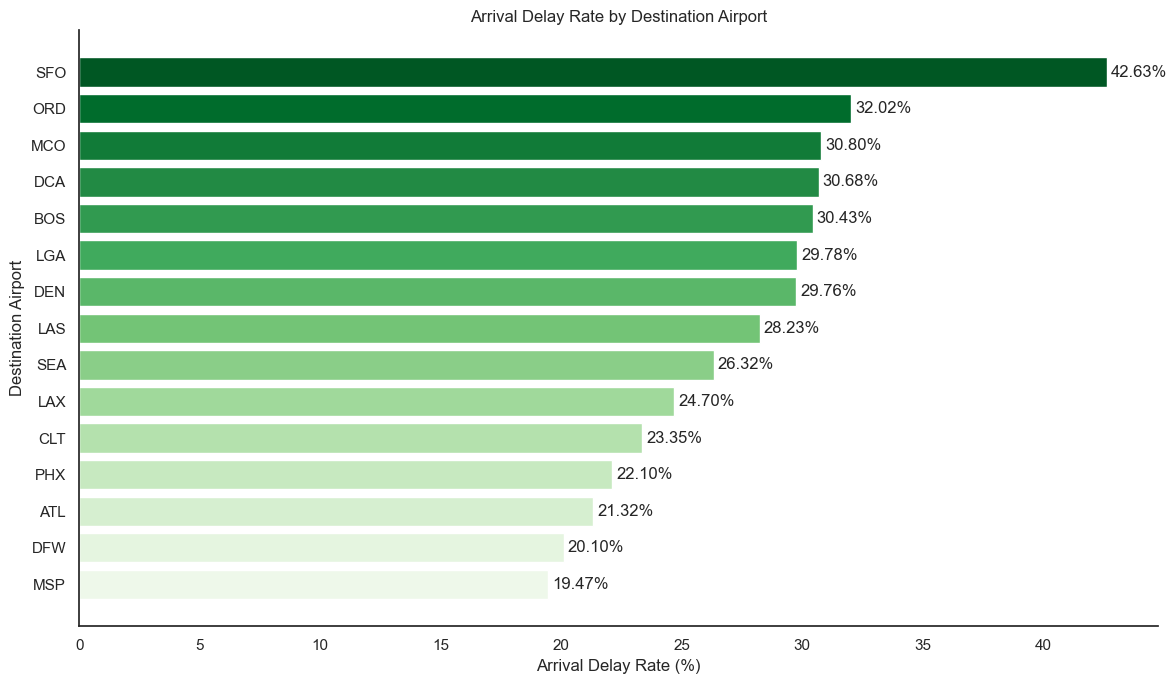

In [86]:
plot_data = destination_delay_summary.nlargest(
    15,
    'TotalFlights'
).sort_values('DelayRate', ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette(
    'Greens',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['DelayRate'],
    color=colors
)

ax.set_title('Arrival Delay Rate by Destination Airport')
ax.set_xlabel('Arrival Delay Rate (%)')
ax.set_ylabel('Destination Airport')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [87]:
origin_delay_summary = df.groupby('Origin').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

origin_delay_summary['DelayRate'] = (
    origin_delay_summary['DelayedFlights'] /
    origin_delay_summary['TotalFlights'] * 100
).round(2)

origin_delay_summary['AvgArrivalDelay'] = (
    origin_delay_summary['AvgArrivalDelay'].round(2)
)

display(
    origin_delay_summary.nlargest(
        15,
        'TotalFlights'
    ).sort_values(
        'DelayRate',
        ascending=False
    )
)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
Origin,,,,
ORD,32283,11422.0,31.79,35.38
SFO,13396,4627.0,23.17,34.54
DEN,28076,9241.0,27.32,32.91
CLT,14823,4875.0,28.36,32.89
DCA,11238,3633.0,30.32,32.33
LGA,10210,3248.0,30.94,31.81
MCO,11774,3738.0,28.05,31.75
LAS,13619,4140.0,22.89,30.40
BOS,12651,3818.0,25.62,30.18


### Analysis 07: Arrival Delay Performance by Origin Airport

**Objective**

Evaluate arrival delay performance across the 15 busiest origin airports to identify differences in delay rates and average arrival delay duration.

**Findings**

- ORD recorded the highest arrival delay rate at 35.38%.
- MSP had the lowest arrival delay rate at 20.42%.
- ORD also recorded the highest average arrival delay at 31.79 minutes.
- LAX had the lowest average arrival delay at 15.42 minutes.
- ORD handled the highest number of flights, with 32,283 flights.

**Key Insight**

Arrival delay performance varies across origin airports. ORD showed the highest delay rate and average arrival delay among the selected airports, while MSP had the lowest delay rate.

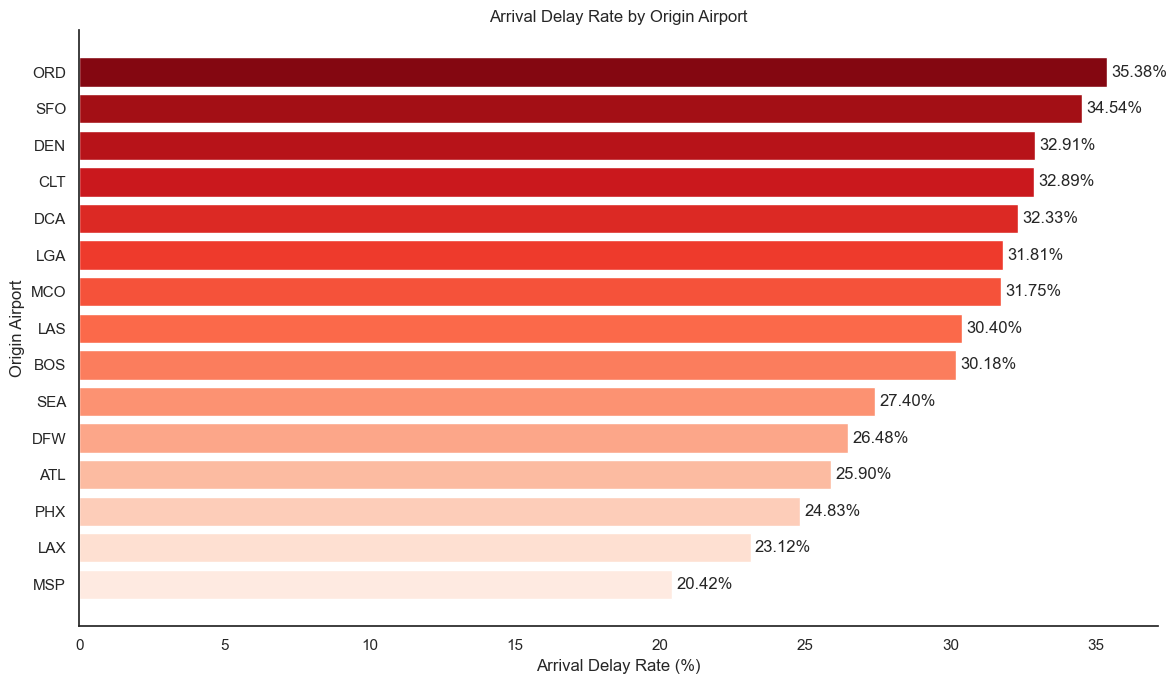

In [93]:
plot_data = origin_delay_summary.nlargest(
    15,
    'TotalFlights'
).sort_values(
    'DelayRate',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette(
    'Reds',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['DelayRate'],
    color=colors
)

ax.set_title('Arrival Delay Rate by Origin Airport')
ax.set_xlabel('Arrival Delay Rate (%)')
ax.set_ylabel('Origin Airport')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [94]:
delay_columns = [
    'CarrierDelay',
    'WeatherDelay',
    'NASDelay',
    'SecurityDelay',
    'LateAircraftDelay'
]

delayed_flights = df[df['ArrDel15'] == 1]

delay_cause_summary = delayed_flights[delay_columns].sum().sort_values(
    ascending=False
)

delay_cause_summary = pd.DataFrame({
    'TotalDelayMinutes': delay_cause_summary,
    'Percentage': (
        delay_cause_summary /
        delay_cause_summary.sum() * 100
    ).round(2)
})

display(delay_cause_summary)

,TotalDelayMinutes,Percentage
LateAircraftDelay,5153146.0,41.32
CarrierDelay,3649911.0,29.27
NASDelay,2905796.0,23.30
WeatherDelay,744942.0,5.97
SecurityDelay,16764.0,0.13


### Analysis 08: Analysis of Arrival Delay Causes

**Objective**

Identify the major contributors to total arrival delay minutes and evaluate their relative impact.

**Findings**

- LateAircraftDelay was the largest contributor, accounting for 41.32% of total recorded delay minutes.
- CarrierDelay ranked second, contributing 29.27%.
- NASDelay accounted for 23.30% of total delay minutes.
- WeatherDelay contributed 5.97%.
- SecurityDelay had the smallest contribution at 0.13%.
- LateAircraftDelay and CarrierDelay together accounted for 70.59% of total recorded delay minutes.

**Key Insight**

LateAircraftDelay is the dominant contributor to total arrival delay minutes, followed by CarrierDelay and NASDelay. These findings suggest that aircraft scheduling and airline operational factors deserve particular attention when investigating flight delays.

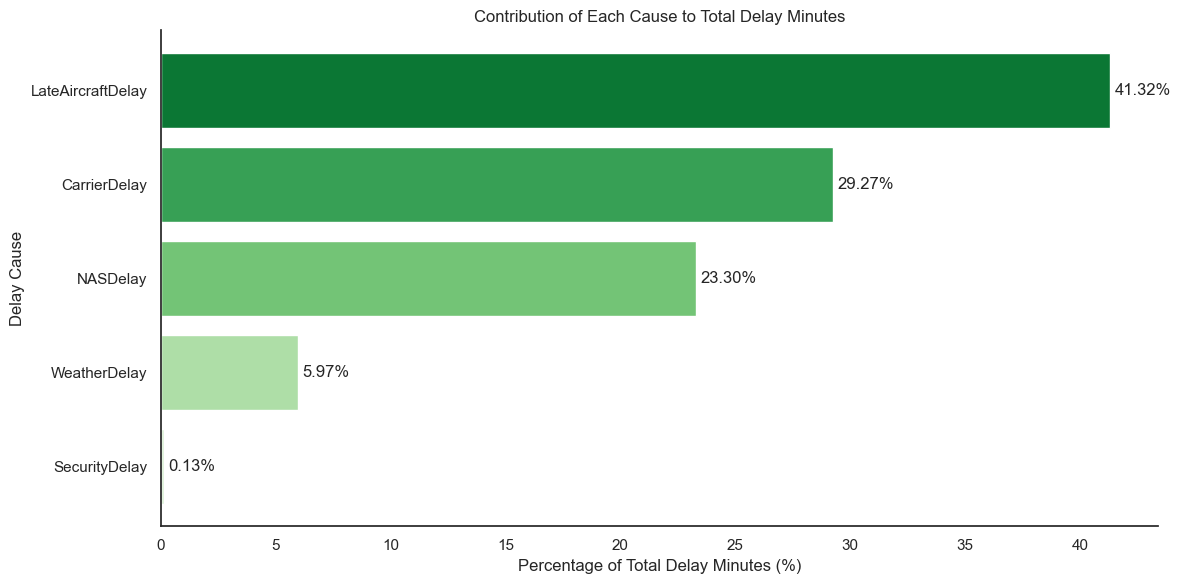

In [96]:
plot_data = delay_cause_summary.sort_values(
    'Percentage',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette(
    'Greens',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['Percentage'],
    color=colors
)

ax.set_title('Contribution of Each Cause to Total Delay Minutes')
ax.set_xlabel('Percentage of Total Delay Minutes (%)')
ax.set_ylabel('Delay Cause')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [97]:
hourly_cause_summary = (
    df[df['ArrDel15'] == 1]
    .groupby('ScheduledDepartureHour')[delay_columns]
    .mean()
    .round(2)
)

display(hourly_cause_summary)

,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
ScheduledDepartureHour,,,,,
0,31.98,5.18,3.84,0.10,24.10
1,11.23,5.65,1.19,0.00,45.92
2,39.90,0.00,2.90,0.00,12.60
3,5.69,1.54,1.85,0.00,40.38
5,78.28,7.26,9.81,0.13,21.96
6,63.63,5.17,12.41,0.22,13.67
7,43.56,3.47,16.22,0.16,13.78
8,32.18,2.54,16.26,0.10,16.45
9,23.53,2.54,18.22,0.05,19.45


### Analysis 09: Delay Causes by Scheduled Departure Hour

**Objective**

Investigate how the average duration of different delay causes varies across scheduled departure hours.

**Findings**

- LateAircraftDelay reached its highest average duration at 20:00, with 45.44 minutes.
- CarrierDelay had its highest average duration at 05:00, reaching 78.28 minutes.
- NASDelay peaked at 15:00, with an average of 24.39 minutes.
- WeatherDelay also reached its highest average at 15:00, with 6.10 minutes.
- SecurityDelay remained negligible across all departure hours.

**Key Insight**

Different delay causes follow different hourly patterns. LateAircraftDelay becomes more prominent during evening hours, while NASDelay generally increases from morning until mid-afternoon. These patterns suggest that operational delay factors vary throughout the day.

**Note**

Average delay durations are calculated among flights with arrival delays of at least 15 minutes. Hours with relatively few delayed flights should be interpreted cautiously.

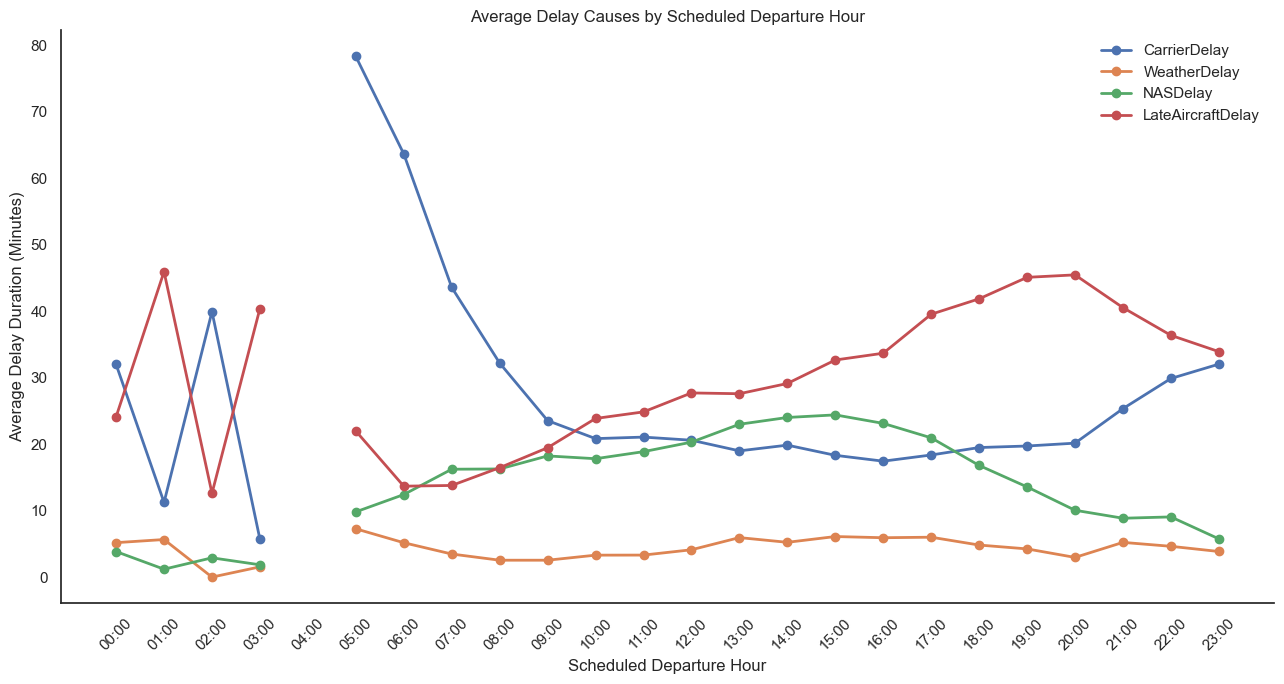

In [98]:
plot_columns = [
    'CarrierDelay',
    'WeatherDelay',
    'NASDelay',
    'LateAircraftDelay'
]

hourly_plot = hourly_cause_summary.reindex(range(24))

fig, ax = plt.subplots(figsize=(13, 7))

for column in plot_columns:
    ax.plot(
        hourly_plot.index,
        hourly_plot[column],
        marker='o',
        linewidth=2,
        label=column
    )

ax.set_title('Average Delay Causes by Scheduled Departure Hour')
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Average Delay Duration (Minutes)')

ax.set_xticks(range(24))
ax.set_xticklabels(
    [f'{hour:02d}:00' for hour in range(24)],
    rotation=45
)

ax.legend(frameon=False)

plt.tight_layout()

display(fig)
plt.close(fig)

In [99]:
airline_cause_summary = (
    df[df['ArrDel15'] == 1]
    .groupby('Reporting_Airline')
    .agg(
        DelayedFlights=('ArrDel15', 'count'),
        CarrierDelay=('CarrierDelay', 'mean'),
        WeatherDelay=('WeatherDelay', 'mean'),
        NASDelay=('NASDelay', 'mean'),
        SecurityDelay=('SecurityDelay', 'mean'),
        LateAircraftDelay=('LateAircraftDelay', 'mean')
    )
    .round(2)
)

display(airline_cause_summary)

,DelayedFlights,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
Reporting_Airline,,,,,,
AA,23564,28.26,4.23,13.88,0.10,42.53
AS,7546,15.49,2.25,12.58,0.23,21.96
B6,7968,24.60,2.35,18.00,0.12,44.19
DL,19449,30.11,3.34,18.91,0.07,20.86
F9,6565,20.09,2.57,20.39,0.00,47.28
G4,2602,30.81,15.99,15.98,0.10,38.16
MQ,5804,16.16,6.54,13.75,0.05,36.81
OH,6104,32.01,11.03,14.02,0.14,47.10
OO,18265,31.61,10.45,22.24,0.20,21.71


### Analysis 10: Delay Causes by Airline

**Objective**

Compare the average contribution of different delay causes across airlines to identify airline-specific delay patterns.

**Findings**

- LateAircraftDelay was the largest contributor for 10 out of 12 airlines.
- F9 recorded the highest average LateAircraftDelay at 47.28 minutes.
- OH had the highest average CarrierDelay at 32.01 minutes.
- UA recorded the highest average NASDelay at 29.28 minutes.
- G4 had the highest average WeatherDelay at 15.99 minutes.
- CarrierDelay was the largest contributor for DL and OO.

**Key Insight**

Delay patterns vary across airlines. LateAircraftDelay is the dominant contributor for most airlines, while CarrierDelay is more prominent for DL and OO. This indicates that different airlines may face different operational delay patterns.

**Note**

Average delay-cause minutes are calculated across all flights with an arrival delay of at least 15 minutes, including zero values for causes that did not contribute to a particular flight.

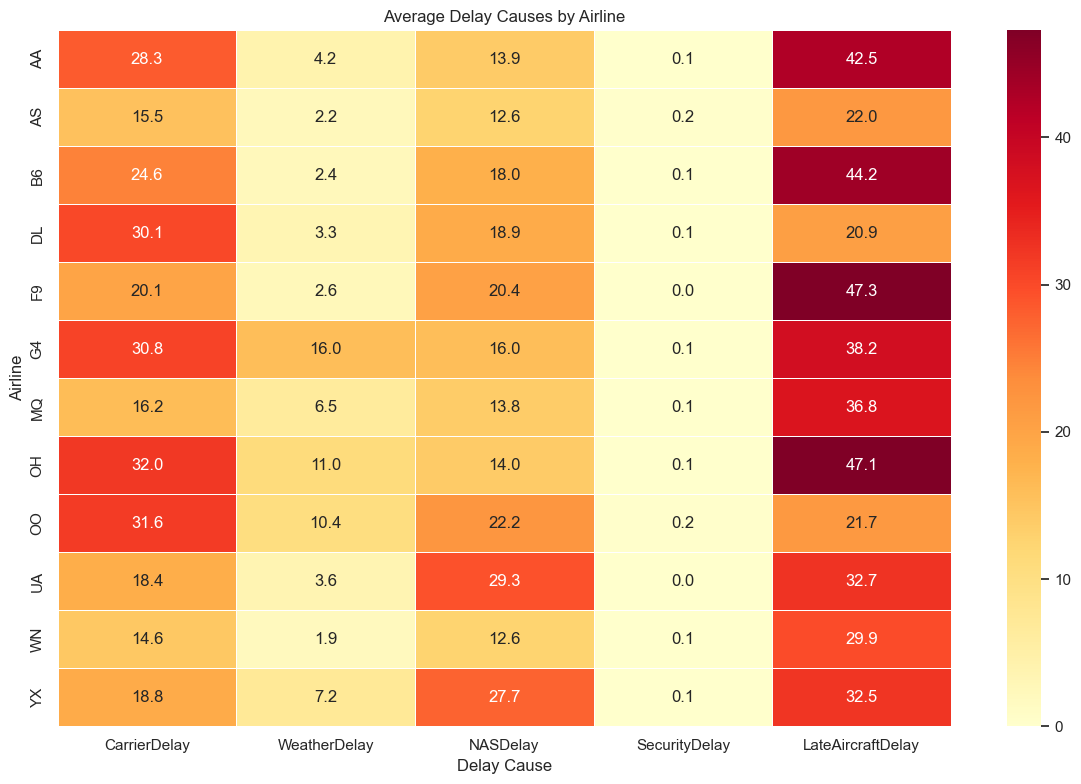

In [100]:
heatmap_data = airline_cause_summary[
    delay_columns
]

fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax
)

ax.set_title('Average Delay Causes by Airline')
ax.set_xlabel('Delay Cause')
ax.set_ylabel('Airline')

plt.tight_layout()

display(fig)
plt.close(fig)

In [101]:
cause_frequency = delayed_flights[delay_columns].gt(0).sum()

cause_frequency_summary = pd.DataFrame({
    'FlightCount': cause_frequency,
    'Percentage': (
        cause_frequency / len(delayed_flights) * 100
    ).round(2)
})

display(
    cause_frequency_summary.sort_values(
        'Percentage',
        ascending=False
    )
)

,FlightCount,Percentage
LateAircraftDelay,86958,54.47
CarrierDelay,81635,51.14
NASDelay,81004,50.74
WeatherDelay,10364,6.49
SecurityDelay,487,0.31


### Analysis 11: Frequency of Each Delay Cause

**Objective**

Determine how frequently each delay cause occurs among flights with arrival delays of at least 15 minutes.

**Findings**

- LateAircraftDelay was the most frequent cause, appearing in 54.47% of delayed flights.
- CarrierDelay appeared in 51.14% of delayed flights.
- NASDelay appeared in 50.74% of delayed flights.
- WeatherDelay was recorded in 6.49% of delayed flights.
- SecurityDelay was the least frequent cause, appearing in only 0.31% of delayed flights.

**Key Insight**

LateAircraftDelay was both the largest contributor to total delay minutes and the most frequently observed delay cause. CarrierDelay and NASDelay were also common, each appearing in approximately half of delayed flights.

**Note**

A flight may have multiple delay causes. Therefore, percentages do not necessarily add up to 100%.

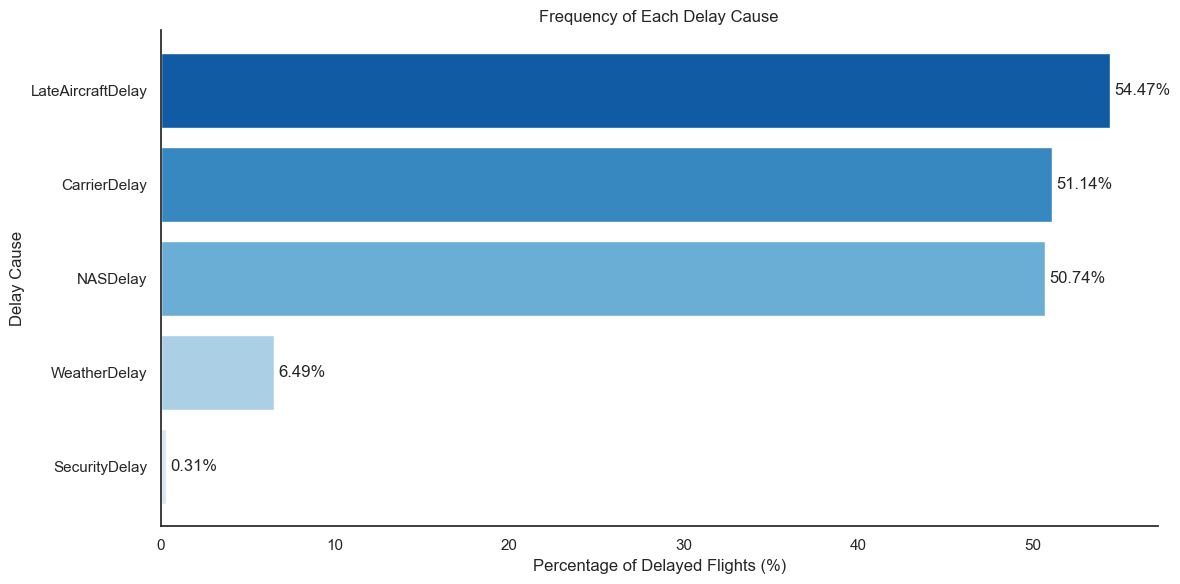

In [102]:
plot_data = cause_frequency_summary.sort_values(
    'Percentage',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette(
    'Blues',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['Percentage'],
    color=colors
)

ax.set_title('Frequency of Each Delay Cause')
ax.set_xlabel('Percentage of Delayed Flights (%)')
ax.set_ylabel('Delay Cause')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [103]:
delay_correlation = df[
    ['DepDelayMinutes', 'ArrDelayMinutes']
].corr(method='pearson')

display(delay_correlation)

,DepDelayMinutes,ArrDelayMinutes
DepDelayMinutes,1.000000,0.980318
ArrDelayMinutes,0.980318,1.000000


### Analysis 12: Relationship Between Departure and Arrival Delays

**Objective**

Investigate the linear relationship between departure delay and arrival delay using Pearson correlation.

**Findings**

- Pearson correlation coefficient: 0.9803.
- A very strong positive linear relationship exists between departure delay minutes and arrival delay minutes.
- Flights with greater departure delays generally experience greater arrival delays.

**Key Insight**

Departure delays are strongly associated with arrival delays. This suggests that delays occurring at the origin airport are generally carried forward to the destination, although some delay recovery may occur during flight operations.

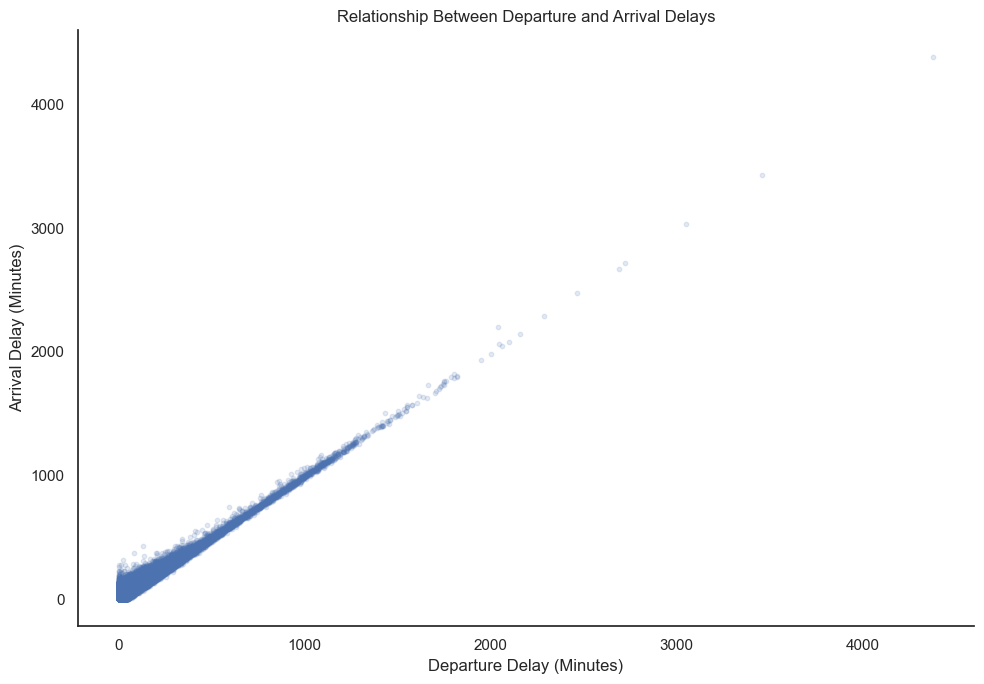

In [106]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    df['DepDelayMinutes'],
    df['ArrDelayMinutes'],
    alpha=0.15,
    s=10
)

ax.set_title('Relationship Between Departure and Arrival Delays')
ax.set_xlabel('Departure Delay (Minutes)')
ax.set_ylabel('Arrival Delay (Minutes)')

plt.tight_layout()

display(fig)
plt.close(fig)

In [107]:
delay_recovery = (
    df['DepDelayMinutes'] - df['ArrDelayMinutes']
)

display(delay_recovery.describe())

count    594207.000000
mean         -0.239878
std          12.666178
min        -295.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          76.000000
dtype: float64

In [108]:
recovery_summary = pd.Series({
    'Recovered Delay': (delay_recovery > 0).sum(),
    'No Change': (delay_recovery == 0).sum(),
    'Additional Delay': (delay_recovery < 0).sum()
})

recovery_percentage = (
    recovery_summary / recovery_summary.sum() * 100
).round(2)

recovery_result = pd.DataFrame({
    'Count': recovery_summary,
    'Percentage': recovery_percentage
})

display(recovery_result)

,Count,Percentage
Recovered Delay,178808,30.09
No Change,295901,49.80
Additional Delay,119498,20.11


### Analysis 13: Departure Delay Recovery

**Objective**

Evaluate whether flights recover from departure delays or experience additional delays during flight operations.

**Findings**

- 30.09% of flights recovered some of their departure delay.
- 49.80% arrived with no change in their delay duration.
- 20.11% experienced additional delays during the journey.

**Key Insight**

Although departure and arrival delays have a very strong positive correlation (0.9803), only 30.09% of flights recovered some of their departure delay. Furthermore, 20.11% experienced additional delays before reaching their destination.

This suggests that departure delays are generally carried forward to arrival, while delay recovery varies across flights.

In [109]:
recovery_by_airline = df.groupby('Reporting_Airline').apply(
    lambda group: pd.Series({
        'TotalFlights': group['DepDelayMinutes'].notna().sum(),
        'RecoveredFlights': (
            (group['DepDelayMinutes'] - group['ArrDelayMinutes']) > 0
        ).sum(),
        'RecoveryRate': (
            (group['DepDelayMinutes'] - group['ArrDelayMinutes']) > 0
        ).mean() * 100
    })
)

recovery_by_airline['RecoveryRate'] = (
    recovery_by_airline['RecoveryRate'].round(2)
)

display(
    recovery_by_airline.sort_values(
        'RecoveryRate',
        ascending=False
    )
)

C:\Users\ZRS\AppData\Local\Temp\ipykernel_6208\3982443050.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  recovery_by_airline = df.groupby('Reporting_Airline').apply(


,TotalFlights,RecoveredFlights,RecoveryRate
Reporting_Airline,,,
WN,115467.0,49448.0,42.49
B6,22316.0,7826.0,32.98
AA,83301.0,27241.0,32.33
AS,30939.0,9576.0,30.51
F9,19749.0,5923.0,29.16
OH,19481.0,6109.0,28.83
UA,73400.0,18818.0,25.40
DL,90317.0,22355.0,24.52
MQ,28886.0,6810.0,23.32


In [110]:
valid_flights = df.dropna(
    subset=['DepDelayMinutes', 'ArrDelayMinutes']
).copy()

valid_flights['DelayRecovery'] = (
    valid_flights['DepDelayMinutes']
    - valid_flights['ArrDelayMinutes']
)

recovery_by_airline = valid_flights.groupby(
    'Reporting_Airline'
).agg(
    TotalFlights=('DelayRecovery', 'count'),
    RecoveredFlights=('DelayRecovery', lambda x: (x > 0).sum()),
    RecoveryRate=('DelayRecovery', lambda x: (x > 0).mean() * 100)
)

recovery_by_airline['RecoveryRate'] = (
    recovery_by_airline['RecoveryRate'].round(2)
)

display(
    recovery_by_airline.sort_values(
        'RecoveryRate',
        ascending=False
    )
)

,TotalFlights,RecoveredFlights,RecoveryRate
Reporting_Airline,,,
WN,114752,49448,43.09
B6,22145,7826,35.34
AA,82801,27241,32.90
OH,19304,6109,31.65
AS,30829,9576,31.06
F9,19638,5923,30.16
UA,72757,18818,25.86
DL,89940,22355,24.86
MQ,28784,6810,23.66


### Analysis 14: Departure Delay Recovery by Airline

**Objective**

Compare airlines based on their ability to recover departure delays during flight operations.

**Findings**

- WN achieved the highest recovery rate at 43.09%.
- B6 ranked second with a recovery rate of 35.34%.
- AA ranked third with 32.90%.
- YX recorded the lowest recovery rate at 21.00%.
- The difference between the highest and lowest recovery rates was 22.09 percentage points.

**Key Insight**

WN demonstrated a considerably higher departure delay recovery rate than other airlines. This indicates that its flights were more likely to recover at least some of their departure delays before arrival.

**Note**

Recovery rates are calculated using only flights with valid departure and arrival delay information. A recovered flight is one where departure delay exceeds arrival delay by any positive amount.

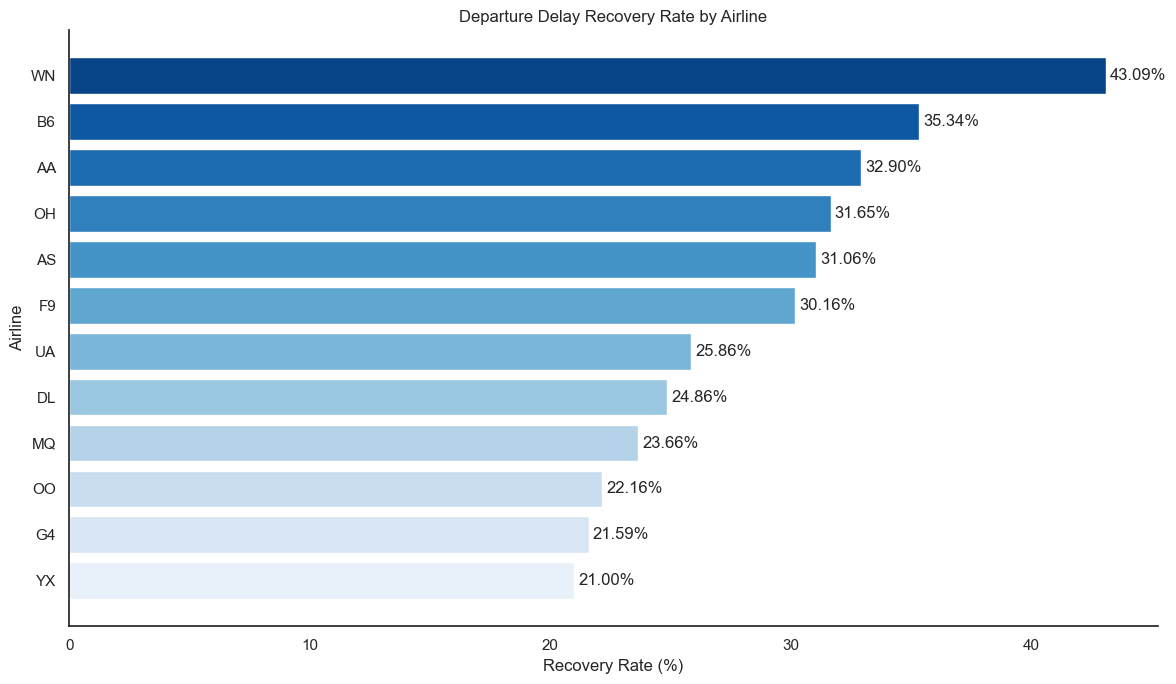

In [111]:
plot_data = recovery_by_airline.sort_values(
    'RecoveryRate',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette(
    'Blues',
    n_colors=len(plot_data)
)

ax.barh(
    plot_data.index,
    plot_data['RecoveryRate'],
    color=colors
)

ax.set_title('Departure Delay Recovery Rate by Airline')
ax.set_xlabel('Recovery Rate (%)')
ax.set_ylabel('Airline')

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.tight_layout()

display(fig)
plt.close(fig)

In [112]:
distance_delay_summary = df.groupby('DistanceGroup').agg(
    TotalFlights=('ArrDelayMinutes', 'count'),
    DelayedFlights=('ArrDel15', 'sum'),
    AvgArrivalDelay=('ArrDelayMinutes', 'mean')
)

distance_delay_summary['DelayRate'] = (
    distance_delay_summary['DelayedFlights'] /
    distance_delay_summary['TotalFlights'] * 100
).round(2)

distance_delay_summary['AvgArrivalDelay'] = (
    distance_delay_summary['AvgArrivalDelay'].round(2)
)

display(distance_delay_summary)

,TotalFlights,DelayedFlights,AvgArrivalDelay,DelayRate
DistanceGroup,,,,
1,67222,16506.0,21.31,24.55
2,135333,36069.0,21.65,26.65
3,120960,32704.0,22.69,27.04
4,97929,26945.0,22.88,27.51
5,64267,17812.0,22.02,27.72
6,27248,7150.0,21.03,26.24
7,27603,8116.0,22.67,29.40
8,14065,3899.0,20.20,27.72
9,9766,2556.0,20.76,26.17


### Analysis 15: Flight Distance and Arrival Delay

**Objective**

Investigate the relationship between flight distance and arrival delay performance using distance groups.

**Findings**

- Distance Group 7 recorded the highest arrival delay rate at 29.40%.
- Distance Group 1 had the lowest arrival delay rate at 24.55%.
- Distance Group 4 recorded the highest average arrival delay at 22.88 minutes.
- Distance Group 11 had the lowest average arrival delay at 19.99 minutes.
- Average arrival delay remained relatively stable across different distance groups.

**Key Insight**

Flight distance does not appear to have a strong or consistent relationship with average arrival delay in this dataset. Longer flights do not necessarily experience longer arrival delays.

**Note**

Differences in flight volume across distance groups should be considered when interpreting the results.

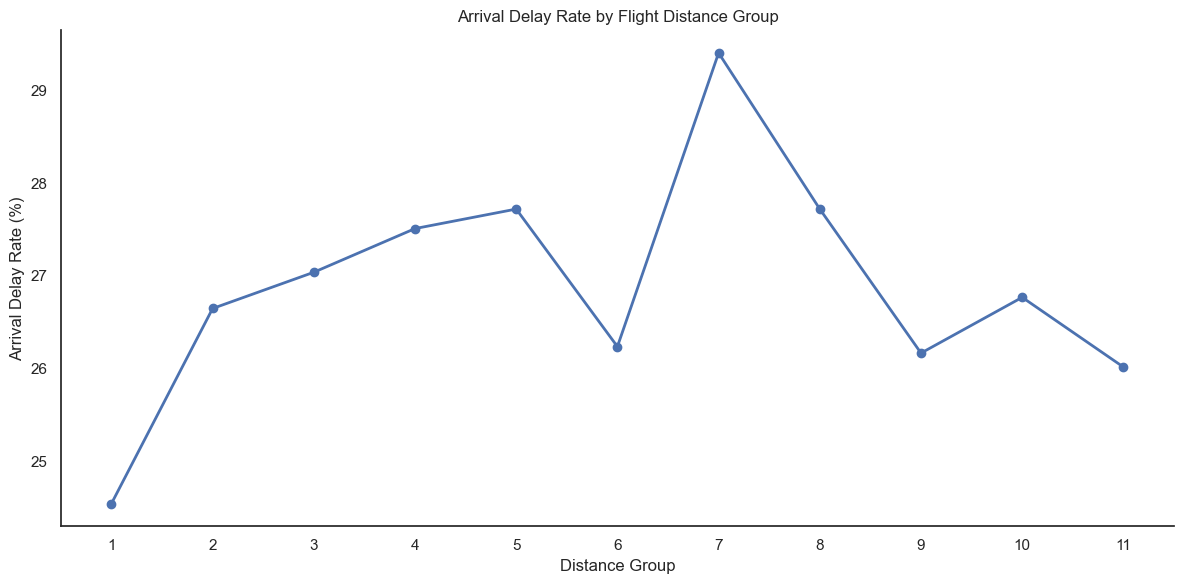

In [113]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    distance_delay_summary.index,
    distance_delay_summary['DelayRate'],
    marker='o',
    linewidth=2
)

ax.set_title('Arrival Delay Rate by Flight Distance Group')
ax.set_xlabel('Distance Group')
ax.set_ylabel('Arrival Delay Rate (%)')

ax.set_xticks(distance_delay_summary.index)

plt.tight_layout()

display(fig)
plt.close(fig)

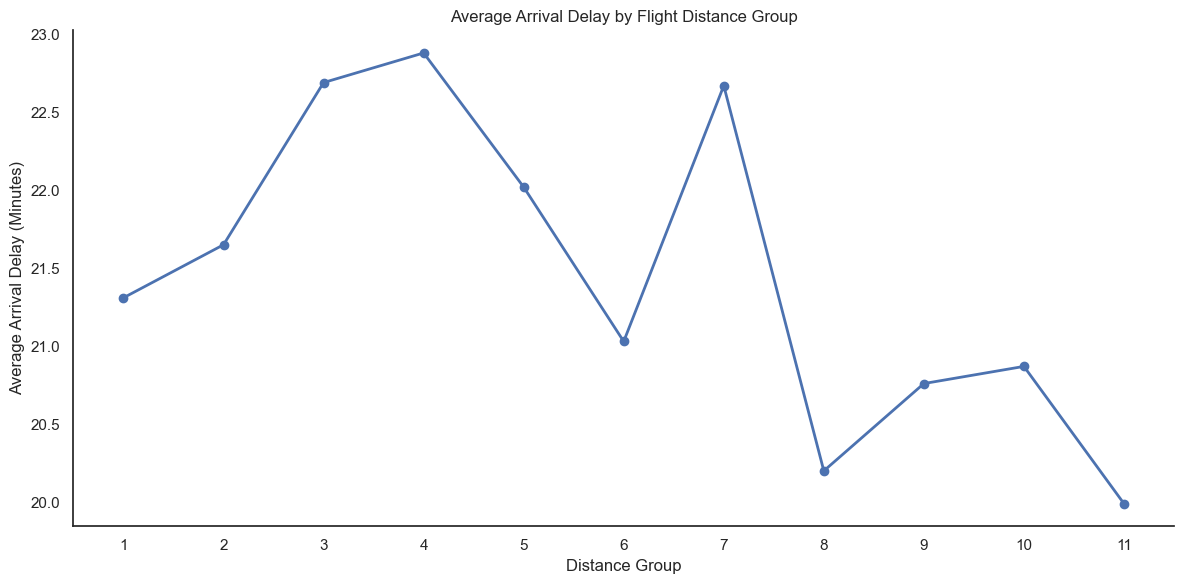

In [116]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    distance_delay_summary.index,
    distance_delay_summary['AvgArrivalDelay'],
    marker='o',
    linewidth=2
)

ax.set_title('Average Arrival Delay by Flight Distance Group')
ax.set_xlabel('Distance Group')
ax.set_ylabel('Average Arrival Delay (Minutes)')

ax.set_xticks(distance_delay_summary.index)

plt.tight_layout()

display(fig)
plt.close(fig)

In [117]:
delayed_departures = df[
    (df['DepDelayMinutes'] > 0) &
    (df['ArrDelayMinutes'].notna()) &
    (df['DistanceGroup'].notna())
].copy()

delayed_departures['DelayRecovery'] = (
    delayed_departures['DepDelayMinutes'] -
    delayed_departures['ArrDelayMinutes']
)

distance_recovery_summary = delayed_departures.groupby('DistanceGroup').agg(
    TotalDelayedDepartures=('DelayRecovery', 'count'),
    RecoveredFlights=('DelayRecovery', lambda x: (x > 0).sum()),
    RecoveryRate=('DelayRecovery', lambda x: (x > 0).mean() * 100),
    AvgDelayRecovery=('DelayRecovery', 'mean')
)

distance_recovery_summary = distance_recovery_summary.round(2)

display(distance_recovery_summary)

,TotalDelayedDepartures,RecoveredFlights,RecoveryRate,AvgDelayRecovery
DistanceGroup,,,,
1,25687,17847,69.48,2.11
2,55055,38585,70.08,1.64
3,50555,35100,69.43,1.50
4,43686,31036,71.04,2.56
5,29115,20663,70.97,2.49
6,12462,8768,70.36,2.39
7,13585,9483,69.80,2.42
8,7005,5013,71.56,3.15
9,4305,2989,69.43,2.30


### Flight Distance and Departure Delay Recovery

The analysis examined whether flight distance is associated with
the ability to recover departure delays.

Key findings:
- Distance Group 8 had the highest recovery rate at 71.56%.
- Distance Group 11 had the lowest recovery rate at 67.54%.
- Average delay recovery ranged from 1.50 to 3.15 minutes.
- No consistent increasing or decreasing trend was observed
  across distance groups.

Overall, flight distance does not show a clear relationship
with departure delay recovery in this dataset.

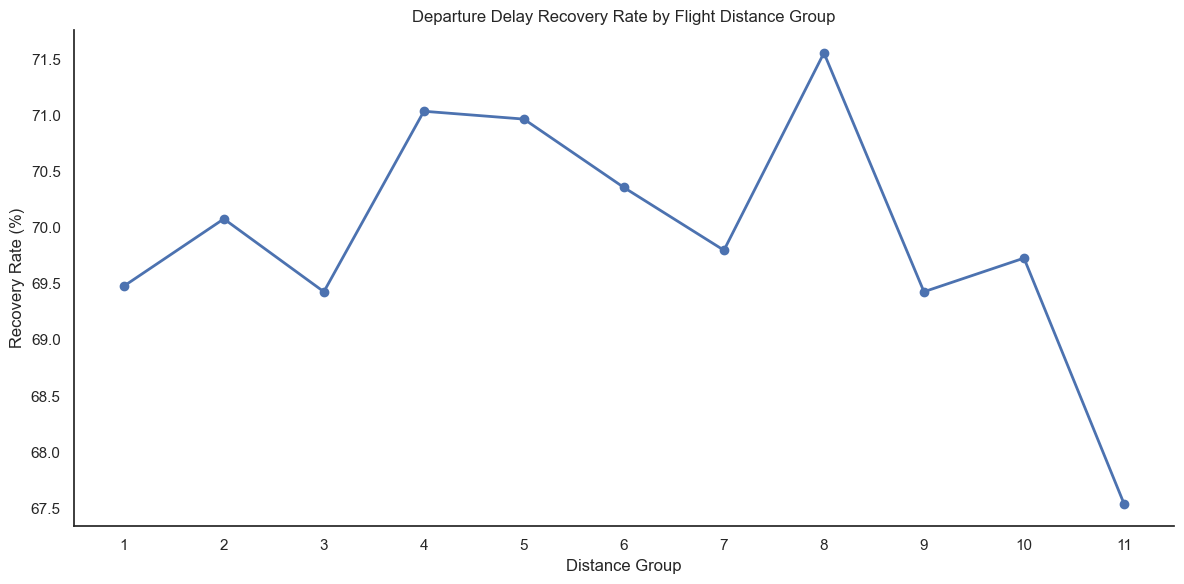

In [118]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    distance_recovery_summary.index,
    distance_recovery_summary['RecoveryRate'],
    marker='o',
    linewidth=2
)

ax.set_title('Departure Delay Recovery Rate by Flight Distance Group')
ax.set_xlabel('Distance Group')
ax.set_ylabel('Recovery Rate (%)')
ax.set_xticks(distance_recovery_summary.index)

plt.tight_layout()
display(fig)
plt.close(fig)

In [119]:
hourly_recovery_summary = delayed_departures.groupby(
    'ScheduledDepartureHour'
).agg(
    TotalDelayedDepartures=('DelayRecovery', 'count'),
    RecoveredFlights=('DelayRecovery', lambda x: (x > 0).sum()),
    RecoveryRate=('DelayRecovery', lambda x: (x > 0).mean() * 100),
    AvgDelayRecovery=('DelayRecovery', 'mean')
)

hourly_recovery_summary = hourly_recovery_summary.round(2)

display(hourly_recovery_summary)

,TotalDelayedDepartures,RecoveredFlights,RecoveryRate,AvgDelayRecovery
ScheduledDepartureHour,,,,
0,438,357,81.51,6.22
1,85,74,87.06,7.75
2,31,27,87.10,7.68
3,21,15,71.43,4.05
5,2479,1939,78.22,3.48
6,7926,5956,75.15,3.23
7,10153,7411,72.99,2.89
8,11219,7996,71.27,2.32
9,11099,7867,70.88,1.98


### Departure Delay Recovery by Scheduled Departure Hour

The analysis revealed a clear variation in delay recovery
performance throughout the day.

Key findings:
- The highest recovery rate was observed at 02:00 (87.10%),
  while the lowest occurred at 15:00 (63.93%).
- Recovery rates generally declined from early morning
  toward the afternoon, then increased during evening hours.
- Average delay recovery followed a similar pattern,
  reaching its lowest value at 15:00 (-0.56 minutes).
- Early morning results should be interpreted cautiously
  due to the relatively small number of delayed flights.

Overall, flights departing during the afternoon showed
weaker delay recovery performance than those departing
during early morning or evening hours.

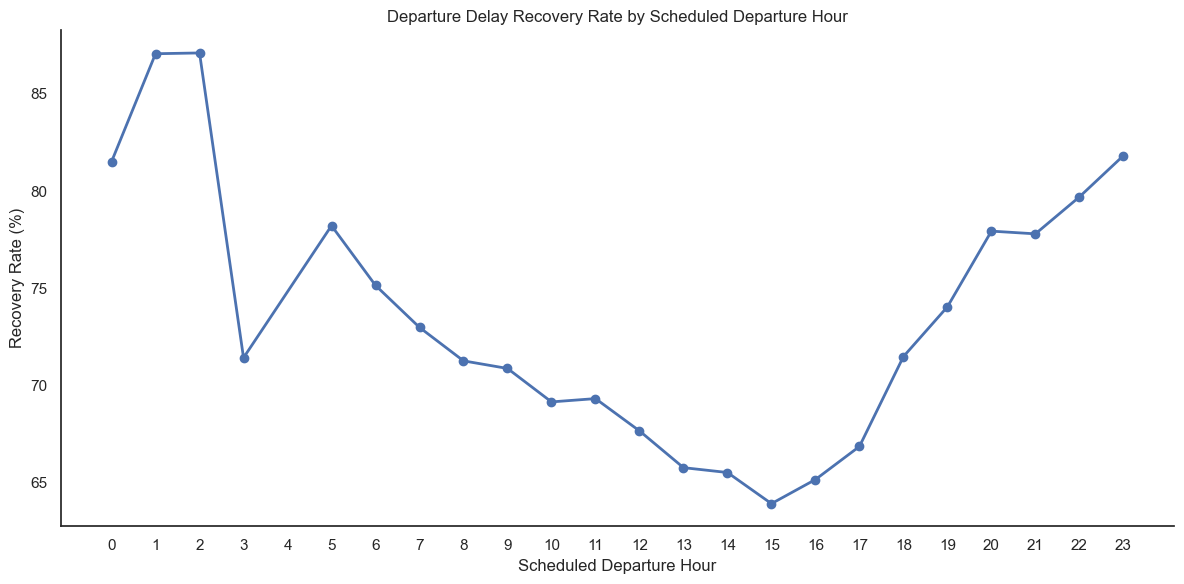

In [120]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    hourly_recovery_summary.index,
    hourly_recovery_summary['RecoveryRate'],
    marker='o',
    linewidth=2
)

ax.set_title('Departure Delay Recovery Rate by Scheduled Departure Hour')
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Recovery Rate (%)')
ax.set_xticks(range(24))

plt.tight_layout()
display(fig)
plt.close(fig)

In [121]:
flight_status_summary = pd.DataFrame({
    'FlightCount': [
        df['Cancelled'].sum(),
        df['Diverted'].sum()
    ]
}, index=['Cancelled', 'Diverted'])

flight_status_summary['Percentage'] = (
    flight_status_summary['FlightCount'] / len(df) * 100
).round(2)

display(flight_status_summary)

,FlightCount,Percentage
Cancelled,11313.0,1.86
Diverted,2869.0,0.47


In [122]:
cancellation_by_airline = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Cancelled', 'count'),
    CancelledFlights=('Cancelled', 'sum')
)

cancellation_by_airline['CancellationRate'] = (
    cancellation_by_airline['CancelledFlights'] /
    cancellation_by_airline['TotalFlights'] * 100
).round(2)

cancellation_by_airline = cancellation_by_airline.sort_values(
    'CancellationRate',
    ascending=False
)

display(cancellation_by_airline)

,TotalFlights,CancelledFlights,CancellationRate
Reporting_Airline,,,
OH,21191,1798.0,8.48
YX,31242,2086.0,6.68
B6,23729,1463.0,6.17
F9,20314,604.0,2.97
AS,31385,476.0,1.52
AA,84271,1021.0,1.21
MQ,29200,336.0,1.15
OO,75426,841.0,1.12
UA,74078,776.0,1.05


### Flight Cancellation Rate by Airline

Cancellation rates varied considerably across airlines.

Key findings:
- OH recorded the highest cancellation rate at 8.48%.
- YX ranked second with a cancellation rate of 6.68%.
- B6 followed with 6.17%.
- G4 had the lowest cancellation rate at 0.36%.
- The cancellation rate of OH was approximately 23 times
  higher than that of G4.

These differences highlight substantial variation in
cancellation patterns across airlines.

In [123]:
diversion_by_airline = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Diverted', 'count'),
    DivertedFlights=('Diverted', 'sum')
)

diversion_by_airline['DiversionRate'] = (
    diversion_by_airline['DivertedFlights'] /
    diversion_by_airline['TotalFlights'] * 100
).round(2)

diversion_by_airline = diversion_by_airline.sort_values(
    'DiversionRate',
    ascending=False
)

display(diversion_by_airline)

,TotalFlights,DivertedFlights,DiversionRate
Reporting_Airline,,,
UA,74078,545.0,0.74
WN,116362,672.0,0.58
AA,84271,449.0,0.53
B6,23729,121.0,0.51
G4,10005,43.0,0.43
OH,21191,89.0,0.42
OO,75426,293.0,0.39
YX,31242,117.0,0.37
F9,20314,72.0,0.35


### Flight Diversion Rate by Airline

Diversion rates varied across airlines, although the
differences were relatively small.

Key findings:
- UA recorded the highest diversion rate at 0.74%.
- WN ranked second with 0.58%.
- AA followed with 0.53%.
- AS had the lowest diversion rate at 0.25%.
- The difference between the highest and lowest rates
  was 0.49 percentage points.

Overall, diversion rates were relatively low across
all airlines, with moderate variation between carriers.

In [124]:
cancellation_by_weekday = df.groupby('DayOfWeek').agg(
    TotalFlights=('Cancelled', 'count'),
    CancelledFlights=('Cancelled', 'sum')
)

cancellation_by_weekday['CancellationRate'] = (
    cancellation_by_weekday['CancelledFlights'] /
    cancellation_by_weekday['TotalFlights'] * 100
).round(2)

cancellation_by_weekday.index = cancellation_by_weekday.index.map({
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
})

display(cancellation_by_weekday)

,TotalFlights,CancelledFlights,CancellationRate
DayOfWeek,,,
Monday,102351,2304.0,2.25
Tuesday,73907,812.0,1.10
Wednesday,74811,403.0,0.54
Thursday,82419,2418.0,2.93
Friday,81773,2229.0,2.73
Saturday,89025,1355.0,1.52
Sunday,104103,1792.0,1.72


### Flight Cancellation Rate by Day of Week

Cancellation rates showed noticeable variation across
different days of the week.

Key findings:
- Thursday had the highest cancellation rate at 2.93%.
- Friday followed with a rate of 2.73%.
- Monday recorded a cancellation rate of 2.25%.
- Wednesday had the lowest cancellation rate at 0.54%.

Overall, cancellations were more frequent on Thursdays
and Fridays, while Wednesdays showed the lowest rate.

In [125]:
diversion_by_weekday = df.groupby('DayOfWeek').agg(
    TotalFlights=('Diverted', 'count'),
    DivertedFlights=('Diverted', 'sum')
)

diversion_by_weekday['DiversionRate'] = (
    diversion_by_weekday['DivertedFlights'] /
    diversion_by_weekday['TotalFlights'] * 100
).round(2)

diversion_by_weekday.index = diversion_by_weekday.index.map({
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
})

display(diversion_by_weekday)

,TotalFlights,DivertedFlights,DiversionRate
DayOfWeek,,,
Monday,102351,483.0,0.47
Tuesday,73907,197.0,0.27
Wednesday,74811,217.0,0.29
Thursday,82419,544.0,0.66
Friday,81773,510.0,0.62
Saturday,89025,385.0,0.43
Sunday,104103,533.0,0.51


### Flight Diversion Rate by Day of Week

Diversion rates varied across the days of the week.

Key findings:
- Thursday recorded the highest diversion rate at 0.66%.
- Friday ranked second with 0.62%.
- Sunday followed with 0.51%.
- Tuesday had the lowest diversion rate at 0.27%.

Interestingly, Thursday and Friday showed relatively
high rates for both cancellations and diversions.

This pattern may indicate shared operational challenges,
although further analysis is needed to identify the causes.

In [126]:
cancellation_by_hour = df.groupby('ScheduledDepartureHour').agg(
    TotalFlights=('Cancelled', 'count'),
    CancelledFlights=('Cancelled', 'sum')
)

cancellation_by_hour['CancellationRate'] = (
    cancellation_by_hour['CancelledFlights'] /
    cancellation_by_hour['TotalFlights'] * 100
).round(2)

display(cancellation_by_hour)

,TotalFlights,CancelledFlights,CancellationRate
ScheduledDepartureHour,,,
0,961,11.0,1.14
1,240,5.0,2.08
2,70,0.0,0.00
3,62,2.0,3.23
5,14382,179.0,1.24
6,41998,718.0,1.71
7,45960,562.0,1.22
8,43033,421.0,0.98
9,35198,349.0,0.99


### Flight Cancellation Rate by Scheduled Departure Hour

Cancellation rates varied throughout the day, with a
noticeable increase during evening and nighttime hours.

Key findings:
- 22:00 recorded the highest cancellation rate at 3.69%.
- 20:00 and 19:00 followed with 3.67% and 3.57%.
- Among high-volume hours, 10:00 had the lowest rate at 0.94%.
- Cancellation rates generally increased after 14:00.

Overall, evening and nighttime departures showed
higher cancellation rates than most daytime departures.

Hours with very low flight volumes should be interpreted
cautiously.

In [127]:
diversion_by_hour = df.groupby('ScheduledDepartureHour').agg(
    TotalFlights=('Diverted', 'count'),
    DivertedFlights=('Diverted', 'sum')
)

diversion_by_hour['DiversionRate'] = (
    diversion_by_hour['DivertedFlights'] /
    diversion_by_hour['TotalFlights'] * 100
).round(2)

display(diversion_by_hour)

,TotalFlights,DivertedFlights,DiversionRate
ScheduledDepartureHour,,,
0,961,3.0,0.31
1,240,1.0,0.42
2,70,0.0,0.00
3,62,0.0,0.00
5,14382,28.0,0.19
6,41998,95.0,0.23
7,45960,107.0,0.23
8,43033,98.0,0.23
9,35198,115.0,0.33


### Flight Diversion Rate by Scheduled Departure Hour

Diversion rates showed a different daily pattern
compared with cancellation rates.

Key findings:
- 13:00 recorded the highest diversion rate at 0.86%.
- 14:00 followed with 0.84%.
- 12:00 ranked third with 0.78%.
- Among high-volume hours, 05:00 had the lowest rate at 0.19%.

Diversion rates generally increased during the morning,
peaked around midday, and declined afterward.

Overall, diversion and cancellation events showed
different temporal patterns.

In [128]:
cancellation_volume = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Cancelled', 'count'),
    CancelledFlights=('Cancelled', 'sum')
)

cancellation_volume['CancellationRate'] = (
    cancellation_volume['CancelledFlights'] /
    cancellation_volume['TotalFlights'] * 100
).round(2)

display(cancellation_volume)

,TotalFlights,CancelledFlights,CancellationRate
Reporting_Airline,,,
AA,84271,1021.0,1.21
AS,31385,476.0,1.52
B6,23729,1463.0,6.17
DL,91186,938.0,1.03
F9,20314,604.0,2.97
G4,10005,36.0,0.36
MQ,29200,336.0,1.15
OH,21191,1798.0,8.48
OO,75426,841.0,1.12


In [129]:
volume_cancellation_corr = cancellation_volume[
    ['TotalFlights', 'CancellationRate']
].corr(method='pearson')

display(volume_cancellation_corr)

,TotalFlights,CancellationRate
TotalFlights,1.000000,-0.482763
CancellationRate,-0.482763,1.000000


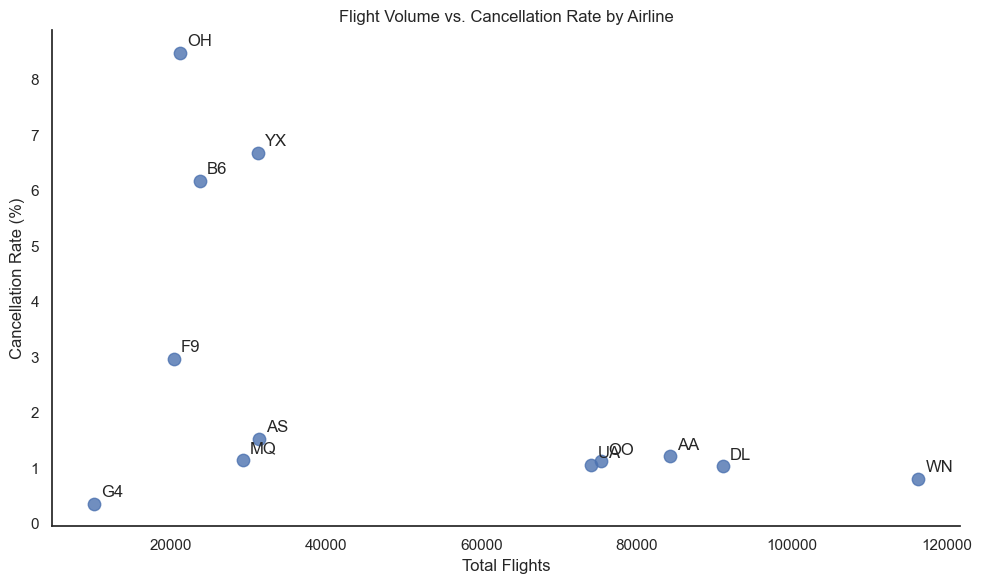

In [130]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    cancellation_volume['TotalFlights'],
    cancellation_volume['CancellationRate'],
    s=80,
    alpha=0.8
)

for airline, row in cancellation_volume.iterrows():
    ax.annotate(
        airline,
        (row['TotalFlights'], row['CancellationRate']),
        xytext=(5, 5),
        textcoords='offset points'
    )

ax.set_title('Flight Volume vs. Cancellation Rate by Airline')
ax.set_xlabel('Total Flights')
ax.set_ylabel('Cancellation Rate (%)')

plt.tight_layout()
display(fig)
plt.close(fig)

### Flight Volume vs. Cancellation Rate

The Pearson correlation coefficient between flight volume
and cancellation rate was -0.483.

Key findings:
- A moderate negative association was observed between
  the number of flights and cancellation rate.
- Airlines with higher flight volumes generally showed
  lower cancellation rates in this dataset.
- WN operated the highest number of flights (116,362)
  with a cancellation rate of 0.81%.
- OH operated 21,191 flights and recorded the highest
  cancellation rate at 8.48%.

This relationship does not imply causation. The analysis
is based on only 12 airlines, so the findings should be
interpreted cautiously.

In [131]:
volume_diversion_corr = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Diverted', 'count'),
    DivertedFlights=('Diverted', 'sum')
)

volume_diversion_corr['DiversionRate'] = (
    volume_diversion_corr['DivertedFlights'] /
    volume_diversion_corr['TotalFlights'] * 100
).round(2)

display(
    volume_diversion_corr[
        ['TotalFlights', 'DiversionRate']
    ].corr(method='pearson')
)

,TotalFlights,DiversionRate
TotalFlights,1.000000,0.454506
DiversionRate,0.454506,1.000000


### Flight Volume vs. Diversion Rate

The Pearson correlation coefficient between flight volume
and diversion rate was +0.455.

Key findings:
- A moderate positive association was observed between
  flight volume and diversion rate.
- Airlines with higher flight volumes tended to show
  higher diversion rates in this dataset.
- This relationship contrasts with the negative association
  observed between flight volume and cancellation rate.

The findings are based on only 12 airlines and do not
establish a causal relationship.

In [132]:
airline_disruption_summary = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Cancelled', 'count'),
    CancellationRate=('Cancelled', lambda x: x.mean() * 100),
    DiversionRate=('Diverted', lambda x: x.mean() * 100)
)

airline_disruption_corr = airline_disruption_summary[
    ['CancellationRate', 'DiversionRate']
].corr(method='pearson')

display(airline_disruption_corr.round(3))

,CancellationRate,DiversionRate
CancellationRate,1.00,-0.07
DiversionRate,-0.07,1.00


### Relationship Between Cancellation and Diversion Rates

The Pearson correlation coefficient between airline
cancellation rates and diversion rates was -0.07.

Key findings:
- Almost no linear association was observed between
  the two operational indicators.
- Airlines with higher cancellation rates did not
  necessarily have higher diversion rates.
- Cancellation and diversion may be influenced by
  different operational and environmental factors.

Overall, cancellation and diversion rates appear to
represent distinct aspects of airline operational performance.

In [137]:
airline_performance = df.groupby('Reporting_Airline').agg(
    TotalFlights=('Reporting_Airline', 'size'),
    FlightsWithArrivalData=('ArrDelayMinutes', 'count'),
    CancelledFlights=('Cancelled', 'sum'),
    DivertedFlights=('Diverted', 'sum'),
    DelayedFlights=('ArrDel15', 'sum')
)

airline_performance['CancellationRate'] = (
    airline_performance['CancelledFlights'] /
    airline_performance['TotalFlights'] * 100
)

airline_performance['DiversionRate'] = (
    airline_performance['DivertedFlights'] /
    airline_performance['TotalFlights'] * 100
)

airline_performance['ArrivalDelayRate'] = (
    airline_performance['DelayedFlights'] /
    airline_performance['FlightsWithArrivalData'] * 100
)

airline_performance = airline_performance.round(2)
airline_performance

,TotalFlights,FlightsWithArrivalData,CancelledFlights,DivertedFlights,DelayedFlights,CancellationRate,DiversionRate,ArrivalDelayRate
Reporting_Airline,,,,,,,,
AA,84271,82801,1021.0,449.0,23564.0,1.21,0.53,28.46
AS,31385,30829,476.0,80.0,7546.0,1.52,0.25,24.48
B6,23729,22145,1463.0,121.0,7968.0,6.17,0.51,35.98
DL,91186,89940,938.0,308.0,19449.0,1.03,0.34,21.62
F9,20314,19638,604.0,72.0,6565.0,2.97,0.35,33.43
G4,10005,9926,36.0,43.0,2602.0,0.36,0.43,26.21
MQ,29200,28784,336.0,80.0,5804.0,1.15,0.27,20.16
OH,21191,19304,1798.0,89.0,6104.0,8.48,0.42,31.62
OO,75426,74292,841.0,293.0,18265.0,1.12,0.39,24.59


### Overall Airline Operational Performance

Airline performance varied across cancellation, diversion,
and arrival delay indicators.

Key findings:
- OH recorded the highest cancellation rate (8.48%),
  while G4 had the lowest (0.36%).
- UA had the highest diversion rate (0.74%),
  while AS had the lowest (0.25%).
- B6 recorded the highest arrival delay rate (35.98%),
  while DL had the lowest (21.62%).
- WN operated the largest number of flights (114,752)
  while maintaining a relatively low cancellation rate (0.81%).

No airline consistently performed best across all
operational indicators.

This highlights the importance of evaluating airline
performance using multiple metrics rather than relying
on a single indicator.

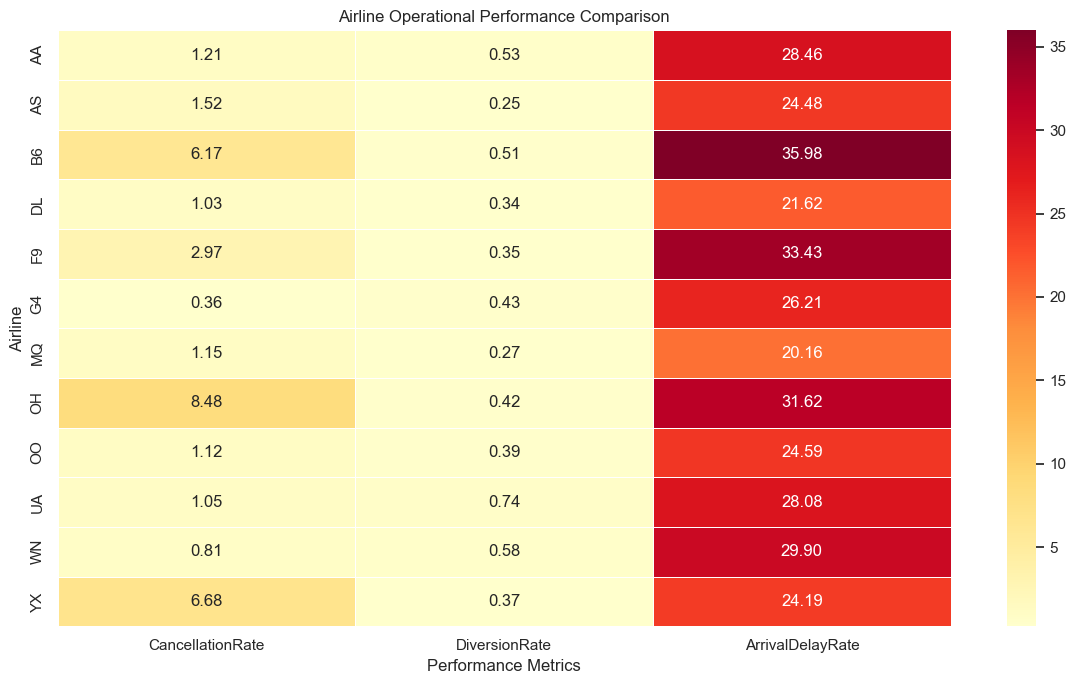

In [138]:
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_data = airline_performance[
    ['CancellationRate', 'DiversionRate', 'ArrivalDelayRate']
]

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax
)

ax.set_title('Airline Operational Performance Comparison')
ax.set_xlabel('Performance Metrics')
ax.set_ylabel('Airline')

plt.tight_layout()
display(fig)
plt.close(fig)

# Executive Summary

This project analyzes airline operational performance using flight data from August 2026.

The analysis focuses on flight delays, cancellation patterns, diversions, airline performance, airport performance, and delay recovery.

## Key Findings

- Arrival delays increased during the evening, reaching their highest rate at 19:00.
- Late Aircraft Delay and Carrier Delay together accounted for 70.59% of total recorded delay-cause minutes.
- Departure and arrival delays showed a very strong positive correlation (Pearson r = 0.98).
- WN achieved the highest departure delay recovery rate among airlines, at 43.09%.
- OH recorded the highest cancellation rate (8.48%), while UA had the highest diversion rate (0.74%).
- DL had the lowest arrival delay rate (21.62%), whereas B6 had the highest (35.98%).

## Business Recommendations

1. Improve aircraft turnaround planning to reduce delays caused by late-arriving aircraft.
2. Review operational resource allocation during evening departure hours.
3. Investigate airport-specific operational conditions at airports with high delay rates.
4. Monitor airline cancellation and diversion patterns separately, as they represent different operational challenges.
5. Develop delay recovery strategies focused on afternoon operations.

## Conclusion

The analysis highlights significant differences in operational performance across airlines, airports, and departure times.

The findings suggest that improving aircraft turnaround processes, managing peak-hour operations, and monitoring airport-specific conditions could help reduce operational disruptions and improve flight punctuality.

Further investigation would be required to establish causal relationships between operational factors and flight disruptions.

In [139]:
overlap_flights = df[
    (df['Cancelled'] == 1) &
    (df['Diverted'] == 1)
]

print("Flights marked as both Cancelled and Diverted:", len(overlap_flights))

Flights marked as both Cancelled and Diverted: 0
